# Nondeterministic Actions: Solving Tic-Tac-Toe with AND-OR-Tree Search

## Introduction 
 
Multiplayer games can be implemented as:
1. __Nondeterministic actions:__ The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)).

We will implement
* __AND-OR-Tree search.__

Each action consists of the move by the player (OR levels in the tree) and all possible (i.e., nondeterministic) responses by the opponents (AND levels). The action therefore results in a set of possible states.

We will search for a __conditional plan__ using AND-OR-Tree search. 

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Solving Tic-Tac-Toe using AND-OR-Tree Search

The opponent can be modeled as part of the environment. The opponent's action as a response to the agent's 
action makes the environment appear non-deterministic (see AIMA page 125 or the slides). The ADS-OR-Tree algorithm uses the following functions:

* `is_goal(state)`: determine if the current board/state has a winner.
* `is_cycle(path)`: determine if we are in a loop (the tic-tac-toe problem has no loops so I do not implement it).
* `results(state, action)`: returns all states following state + action.


### Cycles

The path is typically used for loop checking. We ignore it here since tic-tac-toe does not have cycles.

### Goals

Reaching the goal means that the agent has successfully finished the task. 

For games, `terminal(s)` checks if `s` is a terminal state, but a terminal state can also indicate that 
the player lost (which indicates a failure). This can determined by the 
`utility(s)` function. Tic-tac-toe also has draws and we need to decide if a draw is considered successfully reaching
the goal or a failure.

### Non-deterministic Results

Since the opponent and her moves are part of the environment, `results()` returns for a state $\times$ action combination a set of new states that reflects all possible responses by the opponent.

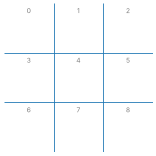


Set of possible state for placing an x at position 4 of an empty board and the opponent's move:


[['o', ' ', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', 'o', ' ', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', 'o', ' ', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', 'o', 'x', ' ', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', 'o', ' ', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', 'o', ' ', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', 'o', ' '],
 [' ', ' ', ' ', ' ', 'x', ' ', ' ', ' ', 'o']]

In [3]:
def results(state, action, player = 'x'):
    """produce the set of states after the provided action for player. 
       It is the set of boards with the action and all possible reactions by the opponent."""
    
    opponent = other(player)
    state = state.copy()
    
    # player's move
    state[action] = player
    
    # opponent reacts
    r = list()
    o_actions = actions(state)
    
    # board is full
    if len(o_actions) < 1 : return [state]
    
    for o_a in o_actions:
        s = state.copy()
        s[o_a] = opponent
        r.append(s)    
    
    return r

show_board(empty_board())

print()
print("Set of possible state for placing an x at position 4 of an empty board and the opponent's move:")
results(empty_board(), 4)

### Recursive AND-OR Search (DFS)

In [4]:
# define global variables for debugging
DEBUG = 1
COUNT = 0 # used to report the number of searched nodes

def and_or_search(state, player = 'x', draw_is_win = True):
    """start the search. Consider draw_is_win a goal state?"""
    global DEBUG, COUNT
    COUNT = 0
    
    plan = or_search(state, player, draw_is_win)
    
    if DEBUG >= 1: 
        print(f"Number of nodes searched: {COUNT}")  
    
    return plan
 

def or_search(state, player, draw_is_win):
    """Or step of the search: the player makes a move. 
    We try all possible action and return a conditional 
    plan for the first action that only has goal states as leaf nodes. 
    If none can be found, then failure (None) is returned.
    
    Note: path is not used in this implementation since tic-tac-toe does not 
    need cycle checking.
    """
    global DEBUG, COUNT
    COUNT += 1
    
    # goal check
    u = utility(state, player)
    if u == -1 or (not draw_is_win and u == 0): return None # failure
     
    # cycles check: tic-tac-toe has no cycles

    # check all possible actions
    for action in actions(state):
        plan = and_search(results(state, action, player), player, draw_is_win)
        if plan is not None: 
            return [action, plan]
    
    # failure
    return None


def and_search(states, player, draw_is_win):
    """And step of the search: Represents all opponent's possible moves. 
    Follow all possible states (call the or step). 
    Return a conditional plan only if all paths lead to a goal state."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return plans only if no state fails
    plans = []
    for s in states:
        # goal check
        u = utility(s, player)
        if u == 1: return "win"  # success
        if draw_is_win and u == 0: return "draw"

        plan = or_search(s, player, draw_is_win)
        
        if plan is None: 
            return None    # found a state that fails so we abandon this subtree!
        plans.append(['if', s, 'then', plan])
        
    return plans

And-or search looks for a subtree (i.e., an action) that guarantees a win and returns a conditional plan for this subtree. If no such subtree exists, no plan is returned. The algorithm only searches a fraction of the game tree since it abandons the current subtree when it finds the first leaf node that is not a win (see `and_search` function).

# Some Tests

## x is about to win

Board:


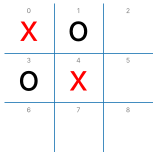


Win or draw:
Number of nodes searched: 22


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'],
   'then',
   [5,
    [['if',
      ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
      'then',
      [7, 'draw']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]]]]

CPU times: user 2.2 ms, sys: 299 μs, total: 2.5 ms
Wall time: 3.01 ms


In [5]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

Why does it play 2 and not 8!!!

In [6]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 30


[2,
 [['if', ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '], 'then', [6, 'win']],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '], 'then', [8, 'win']],
  ['if',
   ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
      'then',
      [6, 'win']]]]],
  ['if', ['x', 'o', 'x', 'o', 'x', ' ', ' ', ' ', 'o'], 'then', [6, 'win']]]]

CPU times: user 2.5 ms, sys: 60 μs, total: 2.56 ms
Wall time: 2.94 ms


**Nhận xét – trường hợp "x sắp thắng"** (x ở ô 0 và 4, o ở ô 1 và 3; đến lượt x).

* Cả hai chế độ đều chọn nước **2**: 22 nút khi `draw_is_win = True` và 30 nút khi `draw_is_win = False`. Nước **8** cũng thắng ngay (đường chéo 0-4-8) nhưng không được chọn – đây chính là câu hỏi "Why does it play 2 and not 8!!!" ở trên.
* Lý do: `or_search` duyệt các hành động theo thứ tự chỉ số tăng dần `[2, 5, 6, 7, 8]` và **trả về hành động đầu tiên có kế hoạch bảo đảm mục tiêu**; thuật toán không tìm nước "tốt nhất" hay "thắng nhanh nhất". Nước 2 tạo thế *song song đe dọa* (fork): đe dọa cùng lúc ô 6 (đường chéo 2-4-6) và ô 8 (đường chéo 0-4-8) nên dù o chặn ô nào, x vẫn thắng ở nước kế tiếp.
* **Kế hoạch điều kiện** có dạng `[hành động, [['if', trạng_thái_sau_phản_ứng_của_o, 'then', kế_hoạch_con], ...]]`: x đánh ô 2, sau đó *với từng phản ứng có thể có của o* (đánh ô 5, 6, 7 hoặc 8) kế hoạch chỉ rõ x phải đánh ô nào tiếp theo và kết thúc bằng `'win'` hoặc `'draw'`. Khi `draw_is_win = True`, một số nhánh con dừng ở `'draw'` vì hòa cũng được tính là đạt mục tiêu; khi `draw_is_win = False` mọi lá đều là `'win'` (nhiều nút hơn vì thuật toán phải loại các nhánh hòa).

## x can draw_is_win if it chooses 7

Board:


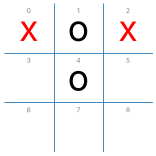


Win or draw:
Number of nodes searched: 64


[7,
 [['if',
   ['x', 'o', 'x', 'o', 'o', ' ', ' ', 'x', ' '],
   'then',
   [5,
    [['if', ['x', 'o', 'x', 'o', 'o', 'x', 'o', 'x', ' '], 'then', [8, 'win']],
     ['if',
      ['x', 'o', 'x', 'o', 'o', 'x', ' ', 'x', 'o'],
      'then',
      [6, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', 'o', ' ', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'],
      'then',
      [6, 'win']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', 'o', 'x', ' '],
   'then',
   [3,
    [['if',
      ['x', 'o', 'x', 'x', 'o', 'o', 'o', 'x', ' '],
      'then',
      [8, 'draw']],
     ['if',
      ['x', 'o', 'x', 'x', 'o', ' ', 'o', 'x', 'o'],
      'then',
      [5, 'draw']]]]],
  ['if',
   ['x', 'o', 'x', ' ', 'o', ' ', ' ', 'x', 'o'],
   'then',
   [3,
    [['if', ['x', 'o', 'x', 'x', 'o', 'o', ' ', 'x', 'o'], 'then', [6, 'win']],
     ['if',
      ['x', '

CPU times: user 4.18 ms, sys: 19 μs, total: 4.2 ms
Wall time: 4.73 ms


In [7]:

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
#board[3] = 'o'
board[4] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [8]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:
Number of nodes searched: 69


None

CPU times: user 2.4 ms, sys: 318 μs, total: 2.72 ms
Wall time: 3.32 ms


**Nhận xét – trường hợp "x cần tìm đường hòa"** (x ở ô 0, 2; o ở ô 1, 4 – o đang đe dọa ô 7 để thắng cột giữa).

* `draw_is_win = True`: AND-OR trả về nước **7** sau 64 nút. Đây là nước duy nhất không thua (chặn cột 1-4-7). Kế hoạch điều kiện có 4 nhánh ứng với phản ứng của o ở ô 3, 5, 6 hoặc 8; các lá là `'win'` hoặc `'draw'`.
* `draw_is_win = False`: trả về `None` sau 69 nút, tức là **không tồn tại kế hoạch bảo đảm thắng** (nếu o chơi đúng thì x chỉ hòa được).
* Hai kết quả cho thấy ý nghĩa của tham số `draw_is_win`: nó quyết định hòa được xem là "thành công" hay "thất bại" của mục tiêu.

## a bad situation

Board:


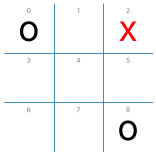


Win or draw:
Number of nodes searched: 155


None

CPU times: user 4.85 ms, sys: 0 ns, total: 4.85 ms
Wall time: 5.55 ms


In [9]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

**Nhận xét – tình huống bất lợi** (o ở ô 0, 8; x ở ô 2; đến lượt x).

* AND-OR trả về `None` sau 155 nút: với **mọi** nước đi của x, o đều có đáp trả dẫn tới chiến thắng, nên không có kế hoạch điều kiện nào tránh được thua (Minimax ở notebook sau cho giá trị −1).
* Ví dụ: nếu x đánh ô 4 để đe dọa ô 6 thì o chặn ở ô 6 và tạo thế fork: đe dọa đồng thời ô 3 (cột 0-3-6) và ô 7 (hàng 6-7-8).
* Hạn chế: AND-OR chỉ trả lời "có kế hoạch" hay "không", nên khi trả về `None` nó **không cho biết nước nào ít tệ nhất**. Vì vậy `and_or_player` bên dưới đánh ngẫu nhiên khi không có kế hoạch.

## Empty board: Only a draw_is_win can be guaranteed

Board:


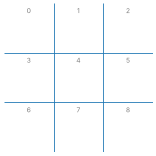


Win or draw:
Number of nodes searched: 966


[0,
 [['if',
   ['x', 'o', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
   'then',
   [2,
    [['if',
      ['x', 'o', 'x', 'o', ' ', ' ', ' ', ' ', ' '],
      'then',
      [4,
       [['if',
         ['x', 'o', 'x', 'o', 'x', 'o', ' ', ' ', ' '],
         'then',
         [6, 'win']],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', 'o', ' ', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', ' ', 'o'],
            'then',
            [7, 'draw']]]]],
        ['if',
         ['x', 'o', 'x', 'o', 'x', ' ', ' ', 'o', ' '],
         'then',
         [5,
          [['if',
            ['x', 'o', 'x', 'o', 'x', 'x', 'o', 'o', ' '],
            'then',
            [8, 'win']],
           ['if',
            ['x', 'o', 'x', 'o', 'x', 'x', ' ', 'o', 'o'],
            'then',
            [6, 'win']]]]],
        ['if',
        

CPU times: user 40.2 ms, sys: 0 ns, total: 40.2 ms
Wall time: 40.6 ms


In [10]:
board = empty_board() 

print("Board:")
show_board(board)

print()
print("Win or draw:")
%time display(and_or_search(board, player = 'x', draw_is_win = True))

In [11]:
print("Win only:")
%time display(and_or_search(board, player = 'x', draw_is_win = False))

Win only:


Number of nodes searched: 16213


None

CPU times: user 365 ms, sys: 7.39 ms, total: 373 ms
Wall time: 374 ms


**Nhận xét – bàn cờ rỗng.**

* `draw_is_win = True`: kế hoạch bắt đầu bằng ô **0** (góc) sau **966** nút (chỉ vài chục mili-giây): x có chiến lược để không bao giờ thua.
* `draw_is_win = False`: phải duyệt **16.213** nút (chậm hơn hơn 10 lần) rồi trả về `None` – **x không thể ép thắng** nếu o chơi đúng, nghĩa là giá trị của Tic-Tac-Toe là **hòa**.
* Tìm kiếm thất bại tốn nhiều nút hơn tìm kiếm thành công vì AND-OR phải chứng minh mọi hành động đều không bảo đảm thắng; khi có kế hoạch thuật toán dừng ngay ở hành động đầu tiên thỏa mãn.

## Experiments

### And-Or Tree Search vs. Random

Put AND-OR search into a wrapper agent function. Note that if AND-OR search cannot guarantee a win then
it does not return a plan, nut `None`. In this case, we do not know what the best (i.e., the least "bad") 
move is, so I make the agent play randomly. Other methods that we will learn about later can determine the utility of a move, even if it does not guarantee a win.

In [12]:
DEBUG = 0

def and_or_player(board, player = 'x'):
    plan = and_or_search(board, player)

    # if there is no plan then we do a random action
    if plan is None: 
        return np.random.choice(actions(board))
    else:
        return plan[0]


print("and-or-search vs. random:")
%time display(play(and_or_player, random_player))

print()
print("random vs. and-or-search")
%time display(play(random_player, and_or_player))

and-or-search vs. random:


{'x': 94, 'o': 0, 'd': 6}

CPU times: user 2.62 s, sys: 3.01 ms, total: 2.62 s
Wall time: 2.63 s

random vs. and-or-search


{'x': 0, 'o': 76, 'd': 24}

CPU times: user 3.98 s, sys: 3.71 ms, total: 3.99 s
Wall time: 4.02 s


AND-OR (x) vs. Random (o): {'x': 98, 'o': 0, 'd': 2, 'sec': 2.4893490540000016, 'ms_per_move': 7.03906025641091, 'nodes_per_move': 314.65527065527067}


Random (x) vs. AND-OR (o): {'x': 0, 'o': 71, 'd': 29, 'sec': 3.7411558100000093, 'ms_per_move': 10.038982427027264, 'nodes_per_move': 466.20540540540543}


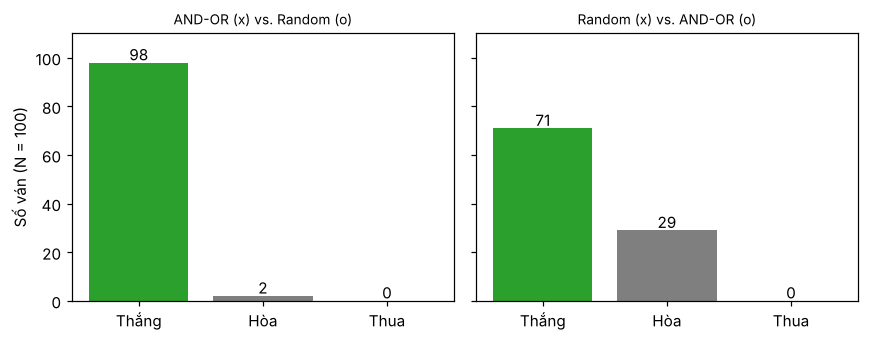


**Kết quả có seed cố định (N = 100 ván mỗi chiều)**

| Chiều đấu | AND-OR thắng | Hòa | AND-OR thua | Thời gian TB / nước đi | Số nút TB / nước đi |
|---|---|---|---|---|---|
| AND-OR đi trước (x) | 98 | 2 | 0 | 7.0 ms | 315 |
| AND-OR đi sau (o)   | 71 | 29 | 0 | 10.0 ms | 466 |


In [13]:
# Chạy lại AND-OR vs. Random với seed cố định, đo thời gian và số nút mỗi nước đi
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown

DEBUG = 0
stats = {"calls": 0, "time": 0.0, "nodes": 0}

def timed(agent):
    def wrapper(board, player = 'x'):
        t = time.perf_counter()
        a = agent(board, player)
        stats["time"] += time.perf_counter() - t
        stats["calls"] += 1
        stats["nodes"] += COUNT          # COUNT = số nút của lần tìm kiếm vừa xong
        return a
    return wrapper

N = 100
np.random.seed(2026)
out = {}
for label, (x, o) in {"AND-OR (x) vs. Random (o)": (timed(and_or_player), random_player),
                      "Random (x) vs. AND-OR (o)": (random_player, timed(and_or_player))}.items():
    stats.update(calls = 0, time = 0.0, nodes = 0)
    t0 = time.perf_counter()
    out[label] = play(x, o, N = N)
    dt = time.perf_counter() - t0
    out[label].update(sec = dt, ms_per_move = 1000 * stats["time"] / stats["calls"], nodes_per_move = stats["nodes"] / stats["calls"])
    print(f"{label}: {out[label]}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), dpi=110, sharey=True)
for ax, (label, r), who in zip(axes, out.items(), ["x", "o"]):
    vals = [r[who], r['d'], r['o' if who == 'x' else 'x']]
    bars = ax.bar(["Thắng", "Hòa", "Thua"], vals, color=["#2ca02c", "#7f7f7f", "#d62728"])
    for b in bars: ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, int(b.get_height()), ha="center")
    ax.set_title(label, fontsize=9); ax.set_ylim(0, 110)
axes[0].set_ylabel(f"Số ván (N = {N})")
plt.tight_layout(); plt.show()

r1, r2 = out["AND-OR (x) vs. Random (o)"], out["Random (x) vs. AND-OR (o)"]
display(Markdown(f"""
**Kết quả có seed cố định (N = {N} ván mỗi chiều)**

| Chiều đấu | AND-OR thắng | Hòa | AND-OR thua | Thời gian TB / nước đi | Số nút TB / nước đi |
|---|---|---|---|---|---|
| AND-OR đi trước (x) | {r1['x']} | {r1['d']} | {r1['o']} | {r1['ms_per_move']:.1f} ms | {r1['nodes_per_move']:.0f} |
| AND-OR đi sau (o)   | {r2['o']} | {r2['d']} | {r2['x']} | {r2['ms_per_move']:.1f} ms | {r2['nodes_per_move']:.0f} |
"""))

**Nhận xét – AND-OR vs. Random (≥ 100 ván mỗi chiều).**

* `and_or_player` **không thua** ván nào ở cả hai chiều (cột "AND-OR thua" bằng 0): ở mọi thời điểm, nếu còn kế hoạch bảo đảm không thua thì thuật toán tìm ra và đi theo nó.
* Nhưng nó không thắng 100%: khi `draw_is_win = True`, **hòa được tính là thành công**, nên `or_search` có thể chọn nước đầu tiên chỉ bảo đảm hòa trong khi đối thủ ngẫu nhiên vẫn có thể mắc sai lầm. Khi đi sau (o), tỉ lệ hòa cao hơn vì `or_search` chỉ đi nước đầu tiên bảo đảm không thua chứ không chọn nước tạo nhiều cơ hội thắng nhất, và người đi sau chỉ thắng được khi x ngẫu nhiên mắc sai lầm.
* Kết quả hơn hẳn Random vs. Random ở Bài 1 (X thắng khoảng 58%, O khoảng 29%), nhưng **chậm**: mỗi nước đi phải dựng lại kế hoạch từ đầu (thời gian trung bình mỗi nước ở bảng trên). Đây là agent phản xạ đơn giản; một agent dựa trên mô hình có thể lưu sẵn kế hoạch cho bàn cờ rỗng.

**Note how slow this is!**

My lazy implementation is a _simple reflex agent_ that recreates a conditional plan every time it is asked for an action. ut since And-Or search already produces a complete conditional plan for the empty board, a better implementation would use a _model-based reflex agent_ that store this precomputed plan and just follow it without more planing.

### And-Or Tree Search vs. And-Or Tree Search

In [14]:
# No randomness -> run only once

%time display(play(and_or_player, and_or_player, N = 1))

{'x': 0, 'o': 0, 'd': 1}

CPU times: user 49.2 ms, sys: 3.98 ms, total: 53.2 ms
Wall time: 53 ms


**Nhận xét – AND-OR vs. AND-OR.** Cả hai bên đều chơi theo kế hoạch "không bao giờ thua" nên ván đấu kết thúc **hòa**. Chạy 1 lần là đủ vì `and_or_player` hoàn toàn tất định khi luôn có kế hoạch (không có yếu tố ngẫu nhiên). Điều này khớp với kết luận ở bàn cờ rỗng: giá trị lý thuyết của Tic-Tac-Toe là hòa.

---
# Lab 05 – Bài 2: Thực hành bổ sung (bảng tổng hợp và minh họa kế hoạch điều kiện)

> Các ô phía trên là nội dung gốc của giảng viên (giữ nguyên). Phần dưới tổng hợp bốn trường hợp kiểm thử có sẵn
> (**X sắp thắng**, **X cần tìm đường hòa**, **tình huống bất lợi**, **bàn cờ rỗng**) cho cả hai chế độ `draw_is_win`,
> và vẽ lại *kế hoạch điều kiện* mà AND-OR Search tạo ra.

In [15]:
# Bảng tổng hợp: 4 trường hợp kiểm thử x 2 chế độ draw_is_win
import time
import pandas as pd

DEBUG = 0

def make_board(**cells):
    """make_board(x=[0,4], o=[1,3]) -> bàn cờ"""
    b = empty_board()
    for symbol, idx in cells.items():
        for i in idx: b[i] = symbol
    return b

TESTS = {
    "X sắp thắng"          : make_board(x=[0, 4], o=[1, 3]),
    "X cần tìm đường hòa"  : make_board(x=[0, 2], o=[1, 4]),
    "Tình huống bất lợi"   : make_board(x=[2], o=[0, 8]),
    "Bàn cờ rỗng"          : empty_board(),
}

def plan_kind(plan):
    """mô tả ngắn gọn kế hoạch: số nhánh phản ứng của đối thủ ở tầng đầu tiên và các loại lá"""
    if plan is None:
        return "không có kế hoạch"
    leaves, branches = set(), 0
    def walk(p):
        nonlocal branches
        if isinstance(p, str):
            leaves.add(p); return
        action, sub = p
        if isinstance(sub, str):
            leaves.add(sub)
        else:
            for _, _, _, child in sub: walk(child)
    action, sub = plan
    branches = 1 if isinstance(sub, str) else len(sub)
    walk(plan)
    return f"{branches} nhánh; lá: {', '.join(sorted(leaves))}"

rows = []
for name, b in TESTS.items():
    for dw in (True, False):
        t = time.perf_counter()
        plan = and_or_search(b, 'x', draw_is_win = dw)
        ms = (time.perf_counter() - t) * 1000
        rows.append({"Trường hợp": name, "draw_is_win": dw,
                     "Nước đi": "—" if plan is None else str(plan[0]),
                     "Số nút": COUNT, "Thời gian (ms)": round(ms, 1),
                     "Kế hoạch điều kiện": plan_kind(plan)})
table = pd.DataFrame(rows)
display(table)

,Trường hợp,draw_is_win,Nước đi,Số nút,Thời gian (ms),Kế hoạch điều kiện
0,X sắp thắng,True,2,22,0.7,"4 nhánh; lá: draw, win"
1,X sắp thắng,False,2,30,0.7,4 nhánh; lá: win
2,X cần tìm đường hòa,True,7,64,1.8,"4 nhánh; lá: draw, win"
3,X cần tìm đường hòa,False,—,69,1.4,không có kế hoạch
4,Tình huống bất lợi,True,—,155,3.2,không có kế hoạch
5,Tình huống bất lợi,False,—,147,3.0,không có kế hoạch
6,Bàn cờ rỗng,True,0,966,24.4,"8 nhánh; lá: draw, win"
7,Bàn cờ rỗng,False,—,16213,348.6,không có kế hoạch


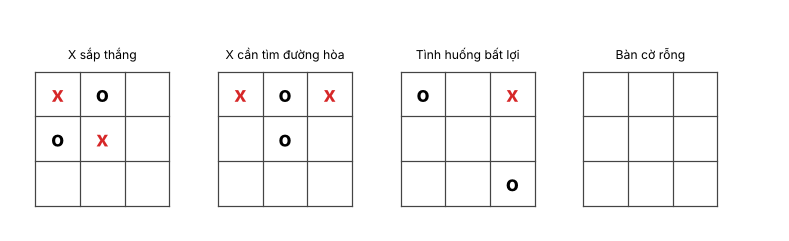

In [16]:
# Vẽ bàn cờ của 4 trường hợp kiểm thử
import matplotlib.pyplot as plt

def draw_mini(ax, board, x0, y0, size = 0.9, title = None, fs = 9):
    """vẽ một bàn cờ 3x3 nhỏ với góc trên-trái tại (x0, y0)"""
    c = size / 3
    for k in range(4):
        ax.plot([x0, x0 + size], [y0 - k * c, y0 - k * c], color = "#444", lw = 0.8)
        ax.plot([x0 + k * c, x0 + k * c], [y0, y0 - size], color = "#444", lw = 0.8)
    for i, v in enumerate(board):
        if v != ' ':
            r, col = divmod(i, 3)
            ax.text(x0 + (col + .5) * c, y0 - (r + .5) * c, v, ha = "center", va = "center",
                    color = "#d62728" if v == 'x' else "black", fontsize = fs, fontweight = "bold")
    if title:
        ax.text(x0 + size / 2, y0 + 0.08, title, ha = "center", va = "bottom", fontsize = 8)

fig, ax = plt.subplots(figsize = (9, 2.6), dpi = 110)
for k, (name, b) in enumerate(TESTS.items()):
    draw_mini(ax, b, k * 1.5, 0, size = 1.1, title = name, fs = 14)
ax.set_xlim(-0.2, 6.1); ax.set_ylim(-1.3, 0.5); ax.set_aspect("equal"); ax.axis("off")
plt.show()

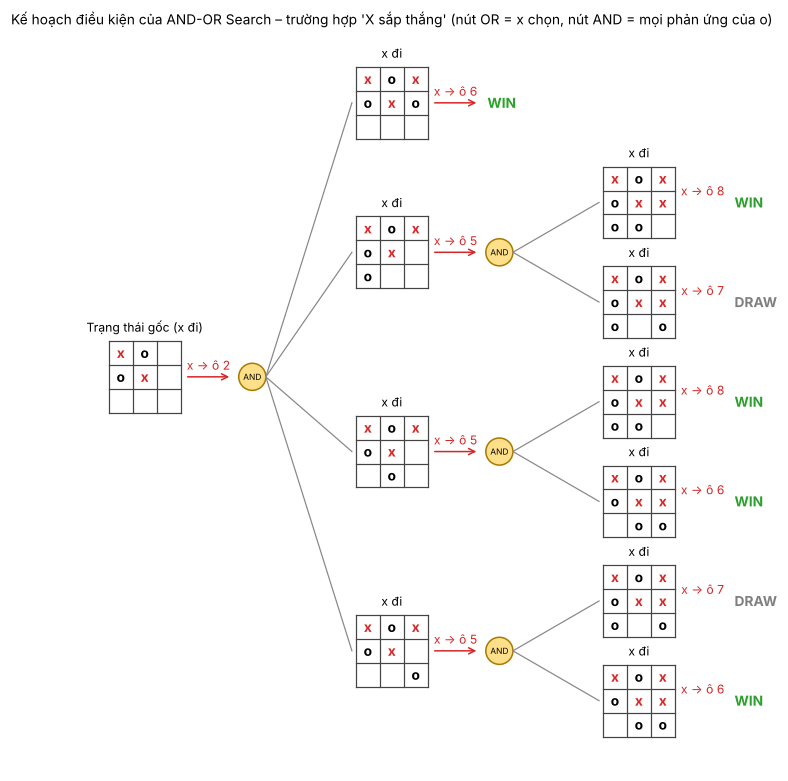

In [17]:
# Minh họa kế hoạch điều kiện (AND-OR tree) cho trường hợp "X sắp thắng" với draw_is_win = True
plan = and_or_search(TESTS["X sắp thắng"], 'x', draw_is_win = True)

def layout(board, plan, depth = 0):
    """trả về cây vẽ được: nút OR (bàn cờ, x đi), hành động, nút AND (các phản ứng của o)"""
    action, sub = plan
    node = {"board": board, "action": action, "depth": depth}
    if isinstance(sub, str):
        node["leaf"] = sub
        node["children"] = []
    else:
        node["leaf"] = None
        node["children"] = [layout(s, child, depth + 1) for _, s, _, child in sub]
    return node

tree = layout(TESTS["X sắp thắng"], plan)

# gán toạ độ: lá dàn đều theo trục y, nút cha ở giữa các con
leaf_counter = [0]
def assign(node):
    if not node["children"]:
        node["y"] = -leaf_counter[0] * 1.25
        leaf_counter[0] += 1
    else:
        for ch in node["children"]: assign(ch)
        ys = [ch["y"] for ch in node["children"]]
        node["y"] = (min(ys) + max(ys)) / 2
    node["x"] = node["depth"] * 3.1
assign(tree)

fig, ax = plt.subplots(figsize = (12, 7.2), dpi = 110)
def draw(node):
    x, y = node["x"], node["y"]
    after = list(node["board"]); after[node["action"]] = 'x'
    draw_mini(ax, node["board"], x, y + 0.45, size = 0.9, title = "x đi" if node["depth"] else "Trạng thái gốc (x đi)")
    ax.annotate("", xy = (x + 1.55, y), xytext = (x + 0.95, y), arrowprops = dict(arrowstyle = "->", color = "#d62728"))
    ax.text(x + 1.25, y + 0.09, f"x → ô {node['action']}", ha = "center", fontsize = 8, color = "#d62728")
    if node["leaf"]:
        ax.text(x + 1.65, y, node["leaf"].upper(), va = "center", fontsize = 9, fontweight = "bold",
                color = "#2ca02c" if node["leaf"] == "win" else "#7f7f7f")
    else:
        ax.add_patch(plt.Circle((x + 1.8, y), 0.17, fc = "#ffe08a", ec = "#aa7a00"))
        ax.text(x + 1.8, y, "AND", ha = "center", va = "center", fontsize = 5.5)
        for ch in node["children"]:
            ax.plot([x + 1.97, ch["x"] - 0.05], [y, ch["y"]], color = "#888", lw = 0.8)
            draw(ch)
draw(tree)
ax.set_title("Kế hoạch điều kiện của AND-OR Search – trường hợp 'X sắp thắng' (nút OR = x chọn, nút AND = mọi phản ứng của o)", fontsize = 9)
ax.set_aspect("equal"); ax.axis("off"); ax.autoscale_view()
plt.tight_layout(); plt.show()

**Cách đọc hình.** Mỗi *nút OR* là một bàn cờ mà x phải chọn nước (x chỉ cần **một** hành động đưa tới thành công). Mũi tên đỏ là hành động mà kế hoạch chọn.
Sau hành động đó là một *nút AND* màu vàng: o có thể đáp trả bằng **bất kỳ** ô trống nào, và kế hoạch phải có nhánh con cho **tất cả** các đáp trả này (nếu thiếu một nhánh thì kế hoạch không "bảo đảm"). Các lá ghi `WIN`/`DRAW` là nhãn mục tiêu mà AND-OR kết thúc.
Nhờ cấu trúc này, AND-OR Search coi đối thủ như **môi trường không xác định** (non-deterministic): nó không giả định o sẽ chơi tốt nhất mà yêu cầu kế hoạch đúng với *mọi* phản ứng của o.